# 05 — Delivery Experience & Satisfaction

**Objective:** test whether late delivery is associated with worse reviews
and lower repeat purchasing.

**Method notes:**
* 'Late' = delivered after `order_estimated_delivery_date`.
* Repeat analysis groups customers by their **first** order's delivery
  experience — otherwise we'd mix cause and effect across orders.
* A windowed variant requires the first order >=180 days before the data
  end, giving every customer comparable follow-up time.
* Results are **associations** — not causal claims.

In [1]:
import sys
from pathlib import Path

# Make the repo's src/ package importable when running from notebooks/.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_loading as dl
from src.config import get_engine
from src.visualization import PALETTE, set_style

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
engine = get_engine()


In [2]:
from src import delivery_analysis as da
orders = dl.load_orders_enriched(engine)
pd.Series(da.delivery_summary(orders))

delivered_with_timestamps   96,470.00
avg_delivery_days               12.50
median_delivery_days            10.00
p90_delivery_days               23.00
avg_promised_days               24.40
late_orders                  6,534.00
late_delivery_pct                6.77
avg_days_late_when_late         10.60
avg_delay_days_all             -11.90
dtype: float64

**Baseline:** Olist usually beats its own estimates — average promise
~24 days vs ~12.5 actual. Only ~6.8% of orders arrive late — but when they
do, they're ~10.6 days late on average.

## Review score: late vs on-time

In [3]:
rev = da.review_by_delivery(orders)
rev

,delivery_outcome,orders_with_review,avg_review_score,pct_score_1_2,pct_score_5,avg_delivery_days,avg_delay_days
0,late,6381,2.27,62.40,16.55,33.80,10.50
1,on_time,89443,4.29,9.26,62.26,10.90,-13.50


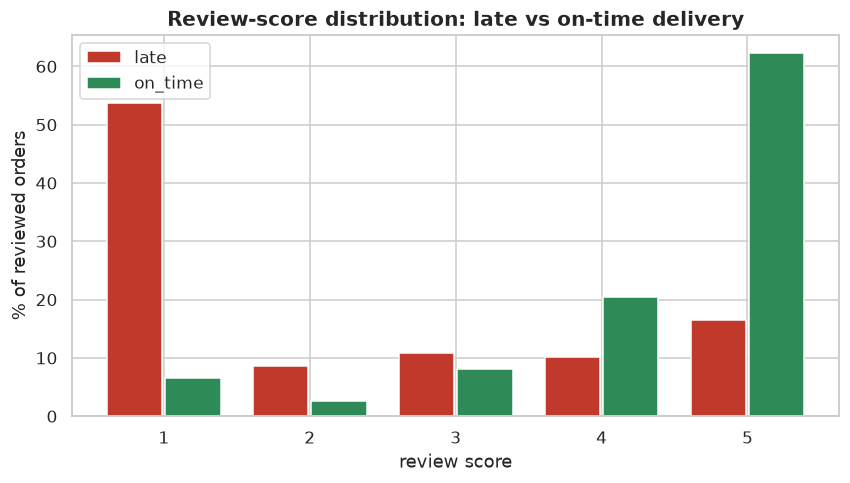

In [4]:
dist = dl.load_table("analytics.review_distribution_by_delivery", engine)
fig, ax = plt.subplots(figsize=(9, 4.5))
for outcome, grp in dist.groupby("delivery_outcome"):
    ax.bar(grp["review_score"] + (-0.2 if outcome == "late" else 0.2),
           grp["pct"], width=0.38, label=outcome,
           color=PALETTE["bad"] if outcome == "late" else PALETTE["good"])
ax.set_title("Review-score distribution: late vs on-time delivery")
ax.set_xlabel("review score"); ax.set_ylabel("% of reviewed orders")
ax.legend(); plt.show()

Striking gap: **62% of late orders score 1-2** (avg 2.27) vs ~9% of
on-time orders (avg 4.29). Delivery experience and satisfaction are
strongly associated in the observational data.

## Repeat purchasing by first-order delivery experience

In [5]:
rep = da.repeat_by_first_delivery(orders, min_window_days=180)
rep

,cohort_label,customers,repeat_customers,repeat_rate_pct,customers_windowed,repeat_rate_pct_windowed
0,first_order_late,6353,158,2.49,3777,2.99
1,first_order_on_time,86997,2643,3.04,52128,4.04


Customers whose first order arrived late repeat at ~2.7% (or ~3.1%
with the 180-day window) vs ~3.3% (~4.1% windowed) for on-time first
orders — a consistent direction in both cuts, roughly a **17-24% lower**
relative repeat rate after a bad first delivery.

## Where lateness concentrates

In [6]:
cat_late = da.late_rate_by(orders, "primary_category", min_orders=500)
cat_late.head(12)

,primary_category,delivered_orders,avg_delivery_days,late_pct,avg_review_score
6,baby,2757,12.70,8.20,4.12
57,office_furniture,1251,20.60,8.10,3.65
26,electronics,2502,12.90,7.70,4.13
56,musical_instruments,608,13.00,7.60,4.24
7,bed_bath_table,9185,13.00,7.50,4.01
43,health_beauty,8615,12.00,7.50,4.23
73,watches_gifts,5473,12.80,7.40,4.12
17,construction_tools_construction,726,10.80,7.40,4.15
5,auto,3792,12.30,7.30,4.15
39,furniture_decor,6200,13.10,7.20,4.08


In [7]:
state_late = da.late_rate_by(orders, "customer_state", min_orders=100)
state_late.head(12)

,customer_state,delivered_orders,avg_delivery_days,late_pct,avg_review_score
1,AL,397,24.50,21.40,3.85
9,MA,717,21.50,17.40,3.83
24,SE,335,21.50,15.20,3.91
16,PI,476,19.40,13.90,3.99
5,CE,1279,21.20,13.80,3.94
4,BA,3256,19.30,12.20,3.93
18,RJ,12350,15.20,12.10,3.97
13,PA,946,23.70,11.20,3.91
7,ES,1995,15.70,10.70,4.08
14,PB,517,20.40,10.40,4.08


## Conclusion

* Late deliveries are ~7% of orders but punch far above their weight in
  dissatisfaction: avg review 2.27 vs 4.29.
* First-order lateness is associated with a meaningfully lower repeat
  rate in both windowed and unwindowed cuts.
* **Cannot claim causation:** late orders may differ in category mix,
  distance, season (e.g. Black Friday congestion) or seller quality —
  all potential confounders. A fair causal claim needs an experiment or
  matched comparison, documented in docs/limitations.md.